# Laboratorio 7: Transformada Rápida de Fourier (FFT)


In [3]:
# Librerías 
from pathlib import Path

import librosa
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image
from scipy import integrate, interpolate
from scipy.fft import fft, fft2, fftfreq, fftshift, ifft2
from scipy.signal import decimate, find_peaks


# Localizar los archivos sin depender de la carpeta desde donde se abra el notebook
def localizar_archivo(nombre):
    """Busca un archivo en la carpeta actual y en las carpetas superiores."""
    subcarpetas = ['', 'Estudiantes/Ramirez_5366', 'Sesiones/Fourier']
    for base in [Path.cwd(), *Path.cwd().parents]:
        for sub in subcarpetas:
            ruta = base / sub / nombre
            if ruta.exists():
                return ruta.resolve()
    raise FileNotFoundError(
        f'No se encontró {nombre}. Ejecute el notebook dentro del repositorio del curso.'
    )

RUTA_AUDIO = localizar_archivo('Nota_CM_piano.mp3')
RUTA_IMAGEN = localizar_archivo('pruebafft.jpeg')

# Frecuencias teóricas de las notas que forman el acorde de Do mayor
NOTAS = {
    'C4': 261.63,
    'E4': 329.63,
    'G4': 392.00,
    'C5': 523.25,
    'E5': 659.26,
    'G5': 783.99,
}

In [4]:
# Cargar la señal de audio
senal, fs = librosa.load(RUTA_AUDIO, sr=None, mono=True)

N = len(senal)
duracion = N / fs

print(f'Frecuencia de muestreo (fs): {fs} Hz')
print(f'Número de muestras (N): {N}')
print(f'Duración de la señal: {duracion:.3f} s')
print(f'Amplitud máxima: {np.max(np.abs(senal)):.4f}')


Frecuencia de muestreo (fs): 44100 Hz
Número de muestras (N): 152064
Duración de la señal: 3.448 s
Amplitud máxima: 0.5653


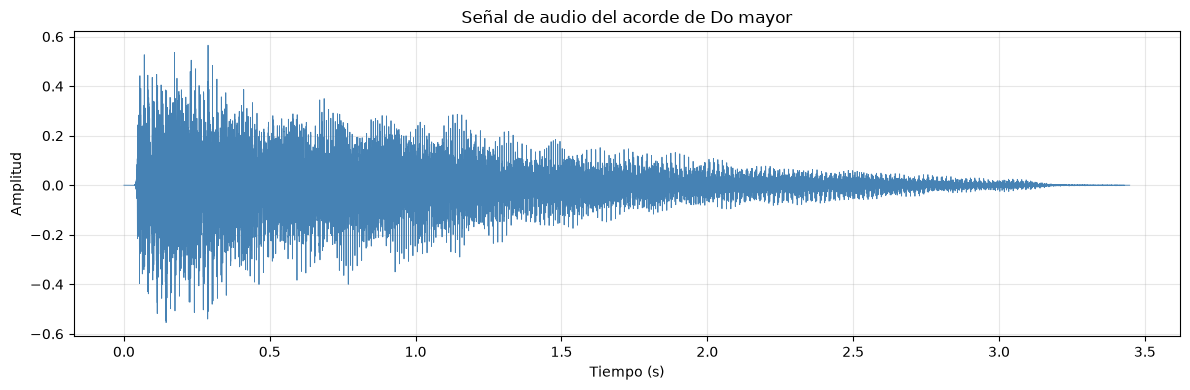

In [5]:
# Eje de tiempo en segundos
t = np.arange(N) / fs

plt.figure(figsize=(12, 4))
plt.plot(t, senal, color='steelblue', linewidth=0.6)
plt.title('Señal de audio del acorde de Do mayor')
plt.xlabel('Tiempo (s)')
plt.ylabel('Amplitud')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [6]:
# Transformada rápida de Fourier
yf = fft(senal)

# Frecuencias correspondientes a cada coeficiente de la FFT
xf = fftfreq(N, 1 / fs)

# Solamente frecuencias positivas
mitad = N // 2
xf_pos = xf[:mitad]
amplitud = (2.0 / N) * np.abs(yf[:mitad])

print(f'Resolución en frecuencia: {xf_pos[1] - xf_pos[0]:.4f} Hz')
print(f'Frecuencia de Nyquist: {fs / 2:.1f} Hz')


Resolución en frecuencia: 0.2900 Hz
Frecuencia de Nyquist: 22050.0 Hz


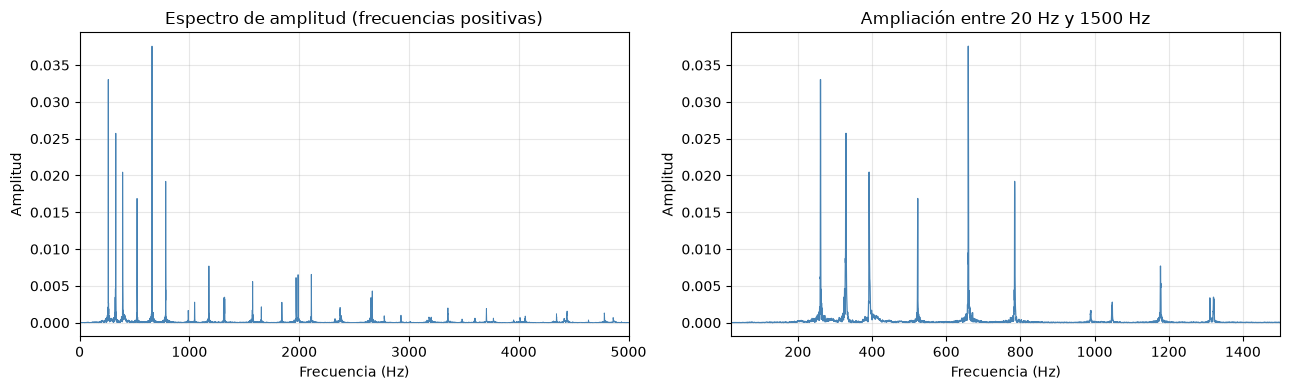

In [7]:
# Espectro completo y ampliación en la zona audible de interés
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].plot(xf_pos, amplitud, color='steelblue', linewidth=0.7)
axes[0].set_title('Espectro de amplitud (frecuencias positivas)')
axes[0].set_xlabel('Frecuencia (Hz)')
axes[0].set_ylabel('Amplitud')
axes[0].set_xlim(0, 5000)
axes[0].grid(alpha=0.3)

axes[1].plot(xf_pos, amplitud, color='steelblue', linewidth=0.9)
axes[1].set_title('Ampliación entre 20 Hz y 1500 Hz')
axes[1].set_xlabel('Frecuencia (Hz)')
axes[1].set_ylabel('Amplitud')
axes[1].set_xlim(20, 1500)
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()


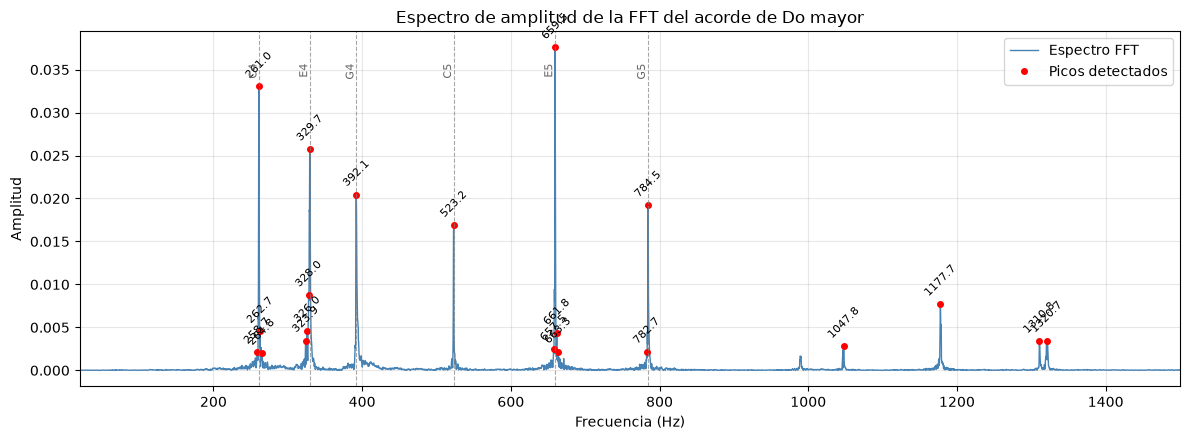

,Frecuencia (Hz),Amplitud
0,659.481534,0.037576
1,261.008523,0.033041
2,329.740767,0.025733
3,392.092803,0.020458
4,784.475616,0.019204
5,523.177083,0.016880
6,328.000710,0.008748
7,1177.728456,0.007699
8,325.970644,0.004637
9,262.748580,0.004537


In [8]:
# Buscar picos en la región de interés
ventana = (xf_pos >= 20) & (xf_pos <= 1500)
f_ventana = xf_pos[ventana]
a_ventana = amplitud[ventana]

picos_fft, _ = find_peaks(
    a_ventana,
    height=0.05 * a_ventana.max(),
    prominence=0.01 * a_ventana.max(),
    distance=5,
)

f_picos = f_ventana[picos_fft]
a_picos = a_ventana[picos_fft]

# Graficar el espectro con los picos detectados
plt.figure(figsize=(12, 4.5))
plt.plot(f_ventana, a_ventana, color='steelblue', linewidth=1, label='Espectro FFT')
plt.plot(f_picos, a_picos, 'o', color='red', markersize=4, label='Picos detectados')

for f, a in zip(f_picos, a_picos):
    plt.annotate(f'{f:.1f}', (f, a), textcoords='offset points',
                 xytext=(0, 6), ha='center', fontsize=8, rotation=45)

for nombre, f0 in NOTAS.items():
    plt.axvline(f0, color='gray', linestyle='--', linewidth=0.8, alpha=0.7)
    plt.text(f0, 0.95 * a_ventana.max(), nombre, fontsize=8,
             rotation=90, ha='right', va='top', color='dimgray')

plt.xlim(20, 1500)
plt.xlabel('Frecuencia (Hz)')
plt.ylabel('Amplitud')
plt.title('Espectro de amplitud de la FFT del acorde de Do mayor')
plt.legend(loc='upper right')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Tabla de picos ordenados por amplitud
orden_fft = np.argsort(a_picos)[::-1]
tabla_fft = pd.DataFrame({
    'Frecuencia (Hz)': f_picos[orden_fft],
    'Amplitud': a_picos[orden_fft],
})
tabla_fft.head(10)


In [9]:
def FT(x, y, fmin=0.1, fmax=1.0, nfreq=100):
    """
    Transformada de Fourier de una señal (x, y).

    Parámetros
    ----------
    x : array_like
        Coordenadas temporales (o espaciales) de la señal.
    y : array_like
        Valores de la señal.
    fmin, fmax : float
        Límites del rango de frecuencias que se quiere analizar.
    nfreq : int
        Número de frecuencias de la grilla.

    Retorna
    -------
    pandas.DataFrame con columnas: w, ReTw, ImTw, AMP y ANG.

    La integral calculada es

        F(w) = (1 / 2*pi) * integral( y(t) * exp(-i*2*pi*w*t) dt ).

    Respecto a la rutina original se cambiaron tres cosas:
      * el rango de frecuencias es configurable;
      * se usa la señal muestreada directamente, sin interpolar en una
        grilla de solo 400 puntos;
      * la integral se calcula con np.trapezoid para todas las frecuencias.
        El resultado es equivalente al de quad, pero es mucho más rápido y
        estable para señales largas y oscilatorias.
    """
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)

    w = np.linspace(fmin, fmax, nfreq)
    F = np.empty(w.size, dtype=complex)

    for i, wi in enumerate(w):
        # Núcleo de Fourier evaluado en todos los tiempos
        nucleo = np.exp(-1j * 2 * np.pi * wi * x)
        # Integral numérica de y(t) * exp(-i*2*pi*w*t)
        F[i] = np.trapezoid(y * nucleo, x) / (2 * np.pi)

    return pd.DataFrame({
        'w': w,
        'ReTw': F.real,
        'ImTw': F.imag,
        'AMP': np.abs(F),
        'ANG': np.angle(F),
    })


In [10]:
# Seleccionar un segmento de la señal donde la nota está bien definida
inicio = int(0.2 * fs)
fin = int(0.8 * fs)
segmento = senal[inicio:fin]

# Diezmar por 4 para reducir el costo computacional
segmento_dec = decimate(segmento, q=4, ftype='fir')
fs_dec = fs / 4
x_dec = np.arange(len(segmento_dec)) / fs_dec

# Aplicar la rutina FT modificada
df_ft = FT(x_dec, segmento_dec, fmin=20, fmax=1200, nfreq=1000)

print(f'Frecuencia de muestreo del segmento: {fs_dec:.1f} Hz')
print(f'Número de muestras del segmento: {len(segmento_dec)}')
print(f'Rango analizado: 20 Hz a 1200 Hz')
df_ft.head()


Frecuencia de muestreo del segmento: 11025.0 Hz
Número de muestras del segmento: 6615
Rango analizado: 20 Hz a 1200 Hz


,w,ReTw,ImTw,AMP,ANG
0,20.000000,8.356787e-07,-0.000003,0.000003,-1.312959
1,21.181181,1.332796e-05,-0.000010,0.000017,-0.633940
2,22.362362,2.166723e-05,0.000006,0.000022,0.251014
3,23.543544,3.865567e-06,0.000011,0.000012,1.239958
4,24.724725,5.379645e-06,-0.000006,0.000008,-0.862396


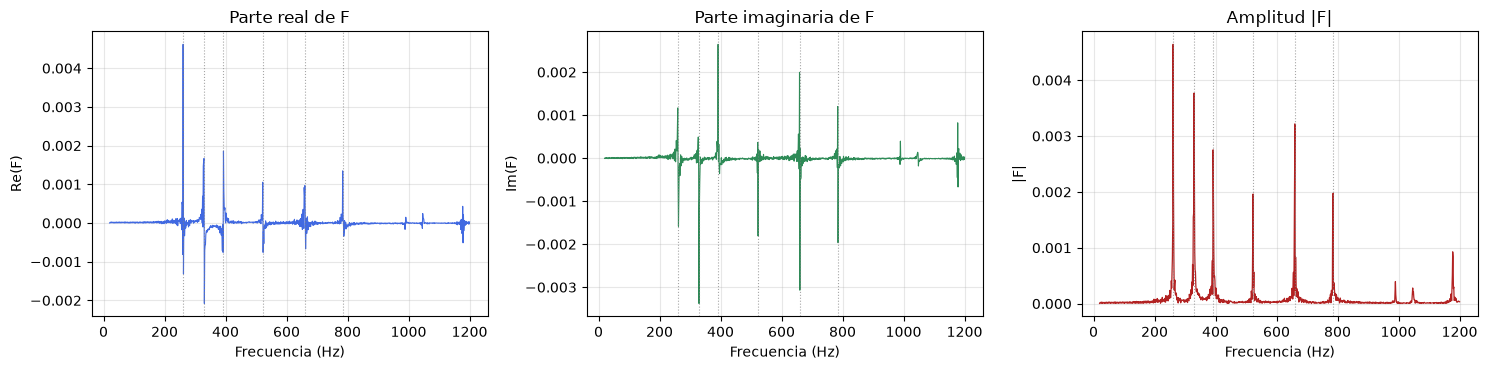

In [11]:
# Visualizar parte real, parte imaginaria y amplitud de la transformada
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))

axes[0].plot(df_ft.w, df_ft.ReTw, color='royalblue', linewidth=0.8)
axes[0].set_title('Parte real de F')
axes[0].set_xlabel('Frecuencia (Hz)')
axes[0].set_ylabel('Re(F)')

axes[1].plot(df_ft.w, df_ft.ImTw, color='seagreen', linewidth=0.8)
axes[1].set_title('Parte imaginaria de F')
axes[1].set_xlabel('Frecuencia (Hz)')
axes[1].set_ylabel('Im(F)')

axes[2].plot(df_ft.w, df_ft.AMP, color='firebrick', linewidth=0.9)
axes[2].set_title('Amplitud |F|')
axes[2].set_xlabel('Frecuencia (Hz)')
axes[2].set_ylabel('|F|')

for ax in axes:
    for f0 in NOTAS.values():
        ax.axvline(f0, color='gray', linestyle=':', linewidth=0.8, alpha=0.7)
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()


In [12]:
# Detectar los picos de la transformada calculada con FT
picos_ft, _ = find_peaks(
    df_ft.AMP,
    height=0.08 * df_ft.AMP.max(),
    prominence=0.02 * df_ft.AMP.max(),
    distance=5,
)

f_ft_picos = df_ft.w.values[picos_ft]
a_ft_picos = df_ft.AMP.values[picos_ft]

orden_ft = np.argsort(a_ft_picos)[::-1]
tabla_ft = pd.DataFrame({
    'Frecuencia (Hz)': f_ft_picos[orden_ft],
    'Amplitud |F|': a_ft_picos[orden_ft],
})

tabla_ft.head(10)


,Frecuencia (Hz),Amplitud |F|
0,260.960961,0.004642
1,329.469469,0.003768
2,660.200200,0.003218
3,392.072072,0.002753
4,785.405405,0.001974
5,523.183183,0.001962
6,1177.557558,0.000927
7,266.866867,0.000421
8,255.055055,0.000410
9,989.749750,0.000395


In [13]:
def pico_mas_cercano(frecuencias, amplitudes, f0):
    """Devuelve la frecuencia y la amplitud del pico más cercano a f0."""
    frecuencias = np.asarray(frecuencias)
    amplitudes = np.asarray(amplitudes)
    idx = np.argmin(np.abs(frecuencias - f0))
    return frecuencias[idx], amplitudes[idx]


filas = []
for nombre, f0 in NOTAS.items():
    f_fft, a_fft = pico_mas_cercano(f_picos, a_picos, f0)
    f_ft, a_ft = pico_mas_cercano(f_ft_picos, a_ft_picos, f0)
    filas.append({
        'Nota': nombre,
        'f teórica (Hz)': f0,
        'f FFT (Hz)': f_fft,
        'f FT (Hz)': f_ft,
        'error FFT (%)': 100 * abs(f_fft - f0) / f0,
        'error FT (%)': 100 * abs(f_ft - f0) / f0,
    })

tabla_comparacion = pd.DataFrame(filas)
tabla_comparacion.round(3)


,Nota,f teórica (Hz),f FFT (Hz),f FT (Hz),error FFT (%),error FT (%)
0,C4,261.63,261.009,260.961,0.238,0.256
1,E4,329.63,329.741,329.469,0.034,0.049
2,G4,392.00,392.093,392.072,0.024,0.018
3,C5,523.25,523.177,523.183,0.014,0.013
4,E5,659.26,659.482,660.200,0.034,0.143
5,G5,783.99,784.476,785.405,0.062,0.181


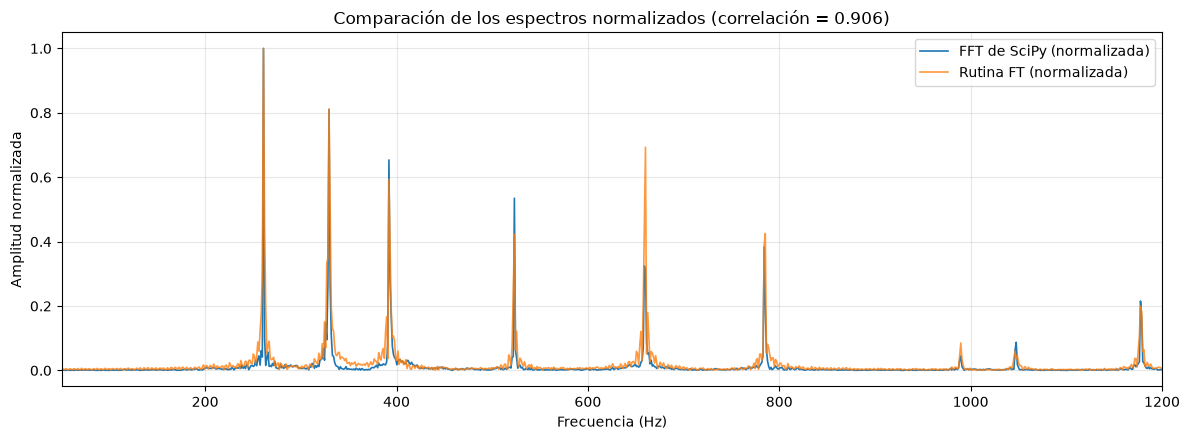

Correlación entre los espectros normalizados: 0.9060


In [14]:
# Comparar la forma de los espectros después de normalizarlos
# La FFT se interpola sobre la grilla de frecuencias de FT para poder compararlas.
fft_interp = np.interp(df_ft.w, xf_pos, amplitud)

seleccion = df_ft.w >= 50
fft_norm = fft_interp / fft_interp[seleccion].max()
ft_norm = df_ft.AMP / df_ft.AMP[seleccion].max()

correlacion = np.corrcoef(fft_norm[seleccion], ft_norm[seleccion])[0, 1]

plt.figure(figsize=(12, 4.5))
plt.plot(df_ft.w[seleccion], fft_norm[seleccion], label='FFT de SciPy (normalizada)', linewidth=1.2)
plt.plot(df_ft.w[seleccion], ft_norm[seleccion], label='Rutina FT (normalizada)', linewidth=1.2, alpha=0.8)
plt.title(f'Comparación de los espectros normalizados (correlación = {correlacion:.3f})')
plt.xlabel('Frecuencia (Hz)')
plt.ylabel('Amplitud normalizada')
plt.xlim(50, 1200)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

print(f'Correlación entre los espectros normalizados: {correlacion:.4f}')


Tamaño de la imagen (alto, ancho): (480, 640)
Tipo de dato: float64
Rango de intensidades: 0 a 255


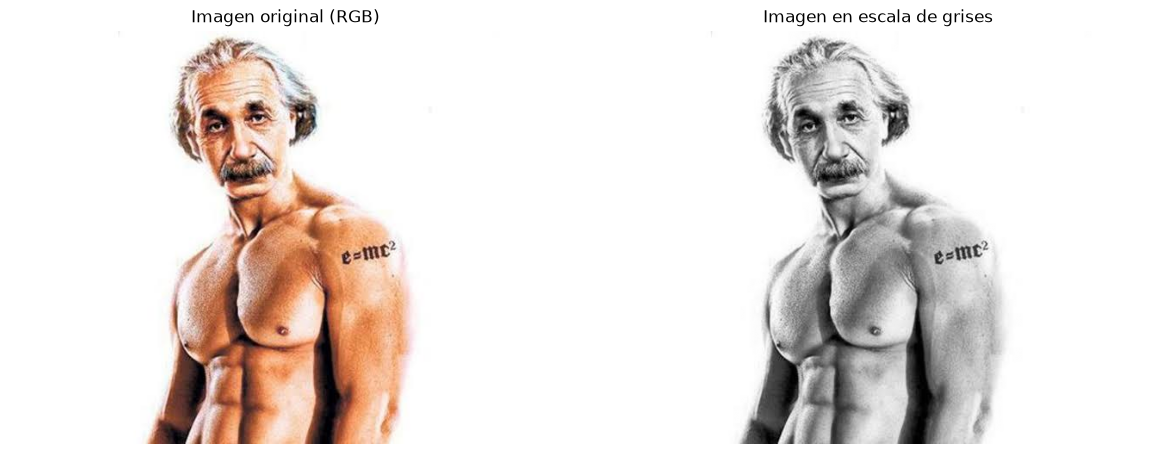

In [15]:
# Cargar la imagen
imagen = Image.open(RUTA_IMAGEN)
imagen_gray = np.asarray(imagen.convert('L'), dtype=float)

print('Tamaño de la imagen (alto, ancho):', imagen_gray.shape)
print('Tipo de dato:', imagen_gray.dtype)
print(f'Rango de intensidades: {imagen_gray.min():.0f} a {imagen_gray.max():.0f}')

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

axes[0].imshow(imagen)
axes[0].set_title('Imagen original (RGB)')
axes[0].axis('off')

axes[1].imshow(imagen_gray, cmap='gray')
axes[1].set_title('Imagen en escala de grises')
axes[1].axis('off')

plt.tight_layout()
plt.show()


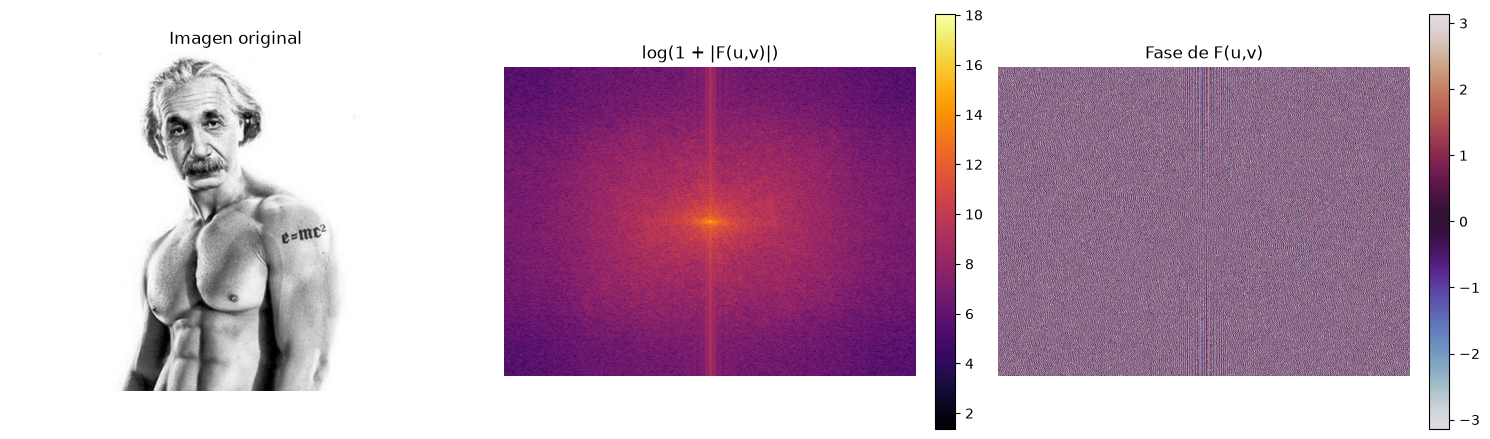

In [16]:
# Transformada de Fourier 2D
F = fft2(imagen_gray)

# Centrar la frecuencia cero para visualizar mejor el espectro
F_shift = fftshift(F)

# Magnitud y fase
magnitud = np.abs(F_shift)
fase = np.angle(F_shift)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

axes[0].imshow(imagen_gray, cmap='gray')
axes[0].set_title('Imagen original')
axes[0].axis('off')

im1 = axes[1].imshow(np.log1p(magnitud), cmap='inferno')
axes[1].set_title('log(1 + |F(u,v)|)')
axes[1].axis('off')
plt.colorbar(im1, ax=axes[1], fraction=0.046, pad=0.04)

im2 = axes[2].imshow(fase, cmap='twilight', vmin=-np.pi, vmax=np.pi)
axes[2].set_title('Fase de F(u,v)')
axes[2].axis('off')
plt.colorbar(im2, ax=axes[2], fraction=0.046, pad=0.04)

plt.tight_layout()
plt.show()


¿Coinciden numéricamente? True
Error máximo absoluto: 1.155e-06
Error relativo máximo: 1.675e-14


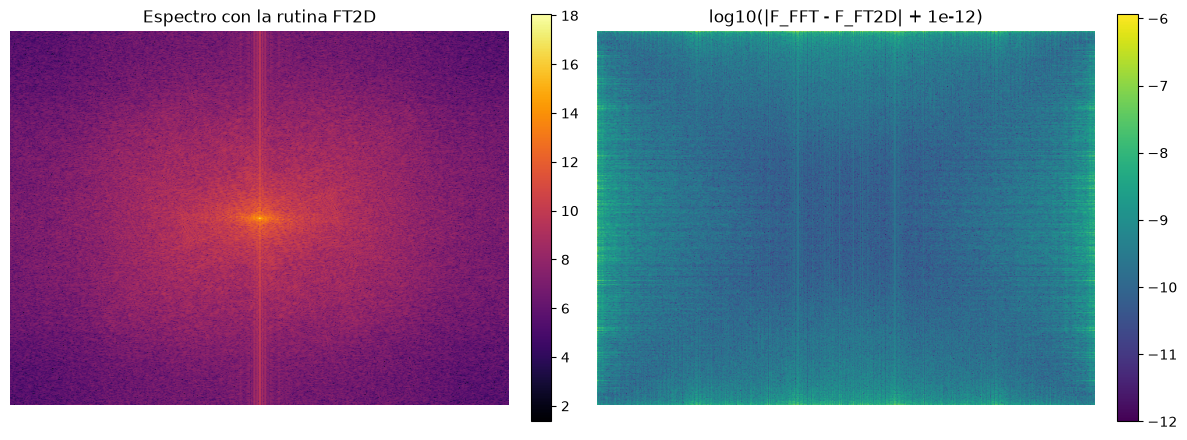

In [17]:
def FT2D(imagen):
    """
    Transformada de Fourier 2D calculada a partir de la definición integral.

    La imagen se interpreta como una función f(x, y) muestreada en una grilla
    con dx = dy = 1 píxel. La integral doble se aproxima por la doble suma

        F(u, v) = sum_m sum_n f[m, n] exp(-i*2*pi*(u*x_n + v*y_m)) dx dy.

    La implementación usa productos matriciales para que sea eficiente.
    """
    f = np.asarray(imagen, dtype=float)
    M, N = f.shape

    dx = dy = 1.0
    x = np.arange(N) * dx
    y = np.arange(M) * dy

    # Frecuencias espaciales en el mismo orden que usa scipy.fft.fft2
    u = np.fft.fftfreq(N, d=dx)
    v = np.fft.fftfreq(M, d=dy)

    # Matrices de Fourier
    Ex = np.exp(-2j * np.pi * np.outer(x, u))
    Ey = np.exp(-2j * np.pi * np.outer(y, v))

    # Doble suma escrita como producto de matrices
    F = dx * dy * (Ey.T @ f) @ Ex

    return F, Ex, Ey


# Calcular la transformada con la rutina propia
F_propia, Ex, Ey = FT2D(imagen_gray)

# Comparar con la FFT de SciPy
diferencia_fft = np.abs(F_propia - F)
error_maximo = diferencia_fft.max()
error_relativo = error_maximo / np.abs(F).max()

print('¿Coinciden numéricamente?', np.allclose(F_propia, F, atol=1e-8, rtol=1e-8))
print(f'Error máximo absoluto: {error_maximo:.3e}')
print(f'Error relativo máximo: {error_relativo:.3e}')

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

im1 = axes[0].imshow(np.log1p(np.abs(fftshift(F_propia))), cmap='inferno')
axes[0].set_title('Espectro con la rutina FT2D')
axes[0].axis('off')
plt.colorbar(im1, ax=axes[0], fraction=0.046, pad=0.04)

im2 = axes[1].imshow(np.log10(diferencia_fft + 1e-12), cmap='viridis')
axes[1].set_title('log10(|F_FFT - F_FT2D| + 1e-12)')
axes[1].axis('off')
plt.colorbar(im2, ax=axes[1], fraction=0.046, pad=0.04)

plt.tight_layout()
plt.show()


Reconstrucción con ifft2 de SciPy
  MSE  = 1.760e-27
  RMSE = 4.195e-14
  PSNR = 315.68 dB
  Error máximo absoluto = 2.132e-13

Reconstrucción con la inversa de FT2D
  MSE  = 1.752e-22
  RMSE = 1.323e-11
  PSNR = 265.70 dB
  Error máximo absoluto = 6.952e-11


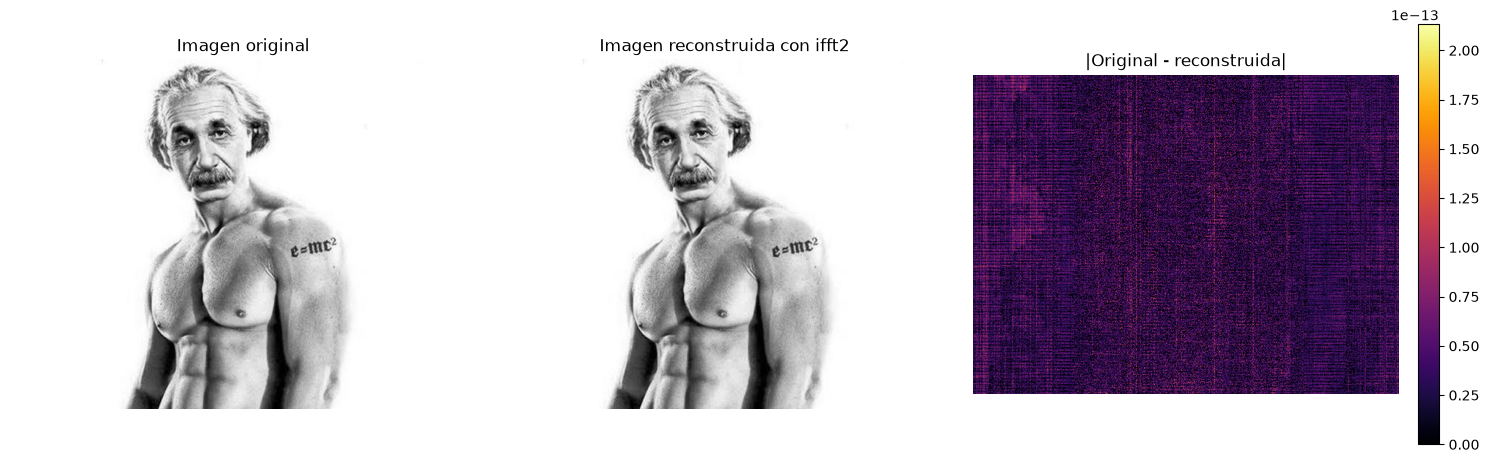

In [18]:
# Transformada inversa con SciPy
imagen_rec = np.real(ifft2(F))

# Transformada inversa a partir de la rutina FT2D
M, N = imagen_gray.shape
imagen_rec_propia = np.real((np.conj(Ey) @ F_propia) @ np.conj(Ex).T) / (M * N)


def metricas_reconstruccion(original, reconstruida):
    """Calcula MSE, RMSE, PSNR y error máximo absoluto."""
    diferencia = original - reconstruida
    mse = np.mean(diferencia**2)
    rmse = np.sqrt(mse)
    psnr = 10 * np.log10(255**2 / mse) if mse > 0 else np.inf
    error_max = np.max(np.abs(diferencia))
    return mse, rmse, psnr, error_max


mse_scipy, rmse_scipy, psnr_scipy, max_scipy = metricas_reconstruccion(imagen_gray, imagen_rec)
mse_propia, rmse_propia, psnr_propia, max_propia = metricas_reconstruccion(imagen_gray, imagen_rec_propia)

print('Reconstrucción con ifft2 de SciPy')
print(f'  MSE  = {mse_scipy:.3e}')
print(f'  RMSE = {rmse_scipy:.3e}')
print(f'  PSNR = {psnr_scipy:.2f} dB')
print(f'  Error máximo absoluto = {max_scipy:.3e}')

print('\nReconstrucción con la inversa de FT2D')
print(f'  MSE  = {mse_propia:.3e}')
print(f'  RMSE = {rmse_propia:.3e}')
print(f'  PSNR = {psnr_propia:.2f} dB')
print(f'  Error máximo absoluto = {max_propia:.3e}')

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

axes[0].imshow(imagen_gray, cmap='gray')
axes[0].set_title('Imagen original')
axes[0].axis('off')

axes[1].imshow(imagen_rec, cmap='gray')
axes[1].set_title('Imagen reconstruida con ifft2')
axes[1].axis('off')

im = axes[2].imshow(np.abs(imagen_gray - imagen_rec), cmap='inferno')
axes[2].set_title('|Original - reconstruida|')
axes[2].axis('off')
plt.colorbar(im, ax=axes[2], fraction=0.046, pad=0.04)

plt.tight_layout()
plt.show()
